# Programming exercise: Bayesian linear regression

**The idea.** Ordinary linear regression finds one best weight vector $\theta$. Here we keep a whole *distribution* over $\theta$ that says which weights fit the data and how sure we are about each. That gives every prediction an error bar.

1. **Before seeing data** we assume the weights are probably near zero: $\theta \sim \mathcal N(0, I)$ (the *prior*).
2. **After seeing data** we update this belief so weights that explain the data become more likely (the *posterior*).
3. **To predict** at a new $x$ we average the predictions of all plausible weights. This gives a predicted value plus a variance.

Normally step 2 needs hard integrals. Here everything is Gaussian and linear, so everything stays Gaussian and we get exact formulas (lecture notes, Section 4.2, eqs. 55–57). The noise level in $\mathcal N(y; x^T\theta, 0.1)$ is a **variance**.

**Setup:** true weights $\theta = [-1, 1]$ (so $y \approx x_2 - x_1$), prior covariance $I$ (each weight is roughly within $\pm 2$ of zero), and a grid over $[-3, 3]^2$ for the heatmaps.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import multivariate_normal

rng = np.random.default_rng(0)

N = 20                            # number of data points
THETA_TRUE = np.array([-1.0, 1.0])
SIGMA_THETA = np.eye(2)           # prior: theta ~ N(0, I)
LIM = 3                           # plots cover [-3, 3]^2

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Grid of 2D input points for the predictive-variance plots
g = np.linspace(-LIM, LIM, 301)
G1, G2 = np.meshgrid(g, g)
GRID = np.column_stack([G1.ravel(), G2.ravel()])

## Helper functions

**`make_dataset`** stretches standard normal draws `z` to the input spread we want, then computes labels $y = x^T\theta + \text{noise}$. The random draws are made once and reused, so differences between settings come from the setting, not from a luckier sample.

**`posterior`** returns the posterior mean (best guess for $\theta$) and covariance (how unsure we are, and in which directions). The reasoning:
- Under the prior, $\theta$ and $y$ are jointly Gaussian, since $y$ is a linear function of $\theta$ plus Gaussian noise.
- The covariance of $y$ is $K = X\Sigma_\theta X^T + \sigma_y^2 I$: spread from not knowing $\theta$ plus spread from noise.
- Observing $y$ leaves $\theta$ Gaussian, with mean $\Sigma_\theta X^T K^{-1} y$ and covariance $\Sigma_\theta - \Sigma_\theta X^T K^{-1} X \Sigma_\theta$.

In practice the mean is like ridge regression, with the noise level setting the penalty. The covariance starts at the prior and shrinks in every direction the data gives information about.

**`predictive`** gives, for a new $x$, the predicted value $x^T\mu_{\theta|D}$ and variance $\sigma_y^2 + x^T\Sigma_{\theta|D}\,x$. The first term is noise we can never remove. The second is our leftover uncertainty about $\theta$; it grows with the size of $x$, because a slightly wrong slope matters more far from the origin.

In [2]:
def make_dataset(z, e, Sigma_x, noise_var):
    # z ~ N(0, I) of shape (N, 2), e ~ N(0, 1) of shape (N,)
    X = z @ np.linalg.cholesky(Sigma_x).T          # x ~ N(0, Sigma_x)
    y = X @ THETA_TRUE + np.sqrt(noise_var) * e    # y ~ N(x^T theta, noise_var)
    return X, y


def posterior(X, y, noise_var, Sigma_theta=SIGMA_THETA):
    # Posterior N(mean, cov) over theta, eqs. (55)-(56)
    K = noise_var * np.eye(len(y)) + X @ Sigma_theta @ X.T
    A = np.linalg.solve(K, X @ Sigma_theta)        # K^{-1} X Sigma_theta (no explicit inverse)
    mean = A.T @ y
    cov = Sigma_theta - Sigma_theta @ X.T @ A
    return mean, cov


def predictive(Xq, mean, cov, noise_var):
    # Posterior predictive p(y | x, D) for each row of Xq, eq. (57)
    mu = Xq @ mean
    var = noise_var + np.einsum("ni,ij,nj->n", Xq, cov, Xq)
    return mu, var

**Plot helpers:** a contour plot of the posterior over $(\theta_1, \theta_2)$, and a heatmap of the predictive variance over $(x_1, x_2)$ with the training inputs on top.

In [3]:
def plot_posterior_pdf(ax, mean, cov, title, center=(0, 0), half=LIM, n=801):
    # Contour plot of the posterior pdf on the square center +- half
    t1 = np.linspace(center[0] - half, center[0] + half, n)
    t2 = np.linspace(center[1] - half, center[1] + half, n)
    T1, T2 = np.meshgrid(t1, t2)
    pdf = multivariate_normal(mean, cov).pdf(np.dstack([T1, T2]))
    cs = ax.contourf(T1, T2, pdf, levels=30, cmap="viridis")
    ax.plot(*THETA_TRUE, "r*", ms=12, label=r"true $\theta$")
    ax.plot(*mean, "wx", ms=8, mew=2, label="posterior mean")
    ax.set(xlabel=r"$\theta_1$", ylabel=r"$\theta_2$", title=title, aspect="equal")
    ax.legend(loc="lower left", fontsize=8)
    plt.colorbar(cs, ax=ax, shrink=0.8, label="density")


def plot_pred_var(ax, X, var, title, levels=30):
    # Heatmap of the predictive variance over x in [-3, 3]^2, with training inputs on top
    cs = ax.contourf(G1, G2, var.reshape(G1.shape), levels=levels, cmap="magma")
    ax.scatter(X[:, 0], X[:, 1], c="cyan", s=15, edgecolor="k", label="training x")
    ax.set(xlabel=r"$x_1$", ylabel=r"$x_2$", title=title, aspect="equal",
           xlim=(-LIM, LIM), ylim=(-LIM, LIM))
    ax.legend(loc="lower left", fontsize=8)
    plt.colorbar(cs, ax=ax, shrink=0.8, label="predictive variance")

## A. Create the dataset

Sample 20 inputs $x \sim \mathcal N(0, I)$ and compute noisy labels with noise variance 0.1.

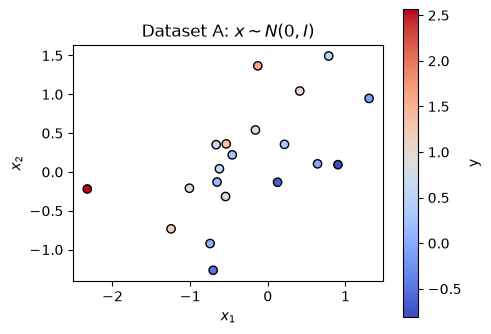

In [4]:
NOISE_VAR = 0.1
SIGMA_X = np.eye(2)

z = rng.standard_normal((N, 2))   # shared input draws
e = rng.standard_normal(N)        # shared noise draws

X_a, y_a = make_dataset(z, e, SIGMA_X, NOISE_VAR)

fig, ax = plt.subplots(figsize=(5, 4))
sc = ax.scatter(X_a[:, 0], X_a[:, 1], c=y_a, cmap="coolwarm", edgecolor="k")
plt.colorbar(sc, label="y")
ax.set(xlabel=r"$x_1$", ylabel=r"$x_2$", title=r"Dataset A: $x \sim N(0, I)$", aspect="equal")
plt.show()

Points are coloured by their label. Since $y \approx x_2 - x_1$, labels rise towards the top-left.

## B. Posterior over $\theta$

We compute the posterior mean and covariance, and check them against the textbook form $(\Sigma_\theta^{-1} + X^TX/\sigma_y^2)^{-1}$ (Bishop eqs. 3.53–3.54) to confirm the code.

posterior mean: [-1.088  1.008]
posterior covariance:
 [[ 0.0085 -0.0048]
 [-0.0048  0.0125]]
matches Bishop's form: True


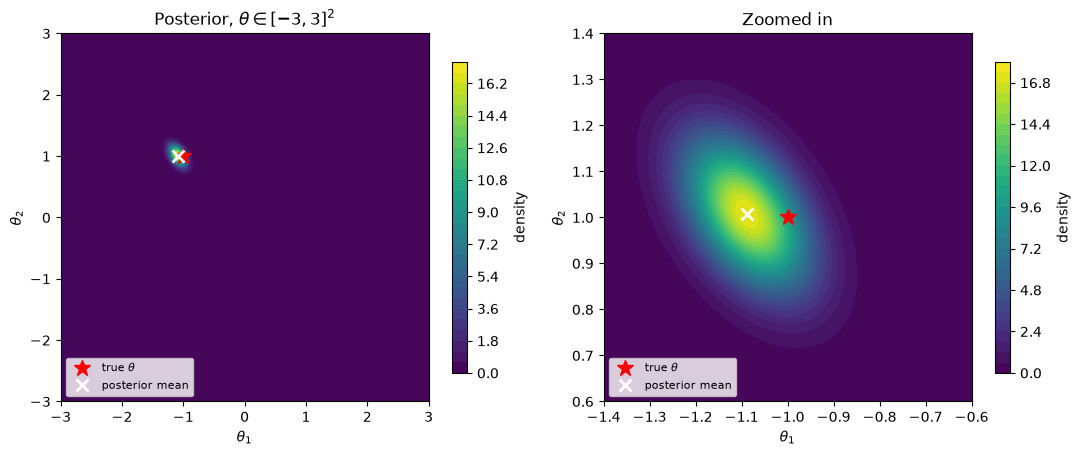

In [5]:
mean_a, cov_a = posterior(X_a, y_a, NOISE_VAR)
print("posterior mean:", mean_a.round(3))
print("posterior covariance:\n", cov_a.round(4))

# Sanity check: Bishop's form (eqs. 3.53-3.54) must give the same answer
cov_b = np.linalg.inv(np.linalg.inv(SIGMA_THETA) + X_a.T @ X_a / NOISE_VAR)
mean_b = cov_b @ X_a.T @ y_a / NOISE_VAR
print("matches Bishop's form:", np.allclose(mean_a, mean_b) and np.allclose(cov_a, cov_b))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_posterior_pdf(axes[0], mean_a, cov_a, r"Posterior, $\theta \in [-3, 3]^2$")
plot_posterior_pdf(axes[1], mean_a, cov_a, "Zoomed in", center=THETA_TRUE, half=0.4)
fig.tight_layout()
fig.savefig(FIG_DIR / "posterior_A.png", dpi=150)
plt.show()

- The mean is close to the true $\theta = [-1, 1]$, and the spread is small (std about 0.1 per weight): 20 points already pin the weights down well.
- In the full $[-3, 3]^2$ window the posterior is just a small dot, so the right plot zooms in.
- The spread is similar in both directions because the inputs vary similarly in $x_1$ and $x_2$. The slight tilt comes from the 20 random points not being spread perfectly evenly.

## C. Posterior predictive $p(y \mid x, D)$

We evaluate the predicted variance $\sigma_y^2 + x^T\Sigma_{\theta|D}\,x$ on the input grid.

predictive variance: min 0.1000, max 0.3750


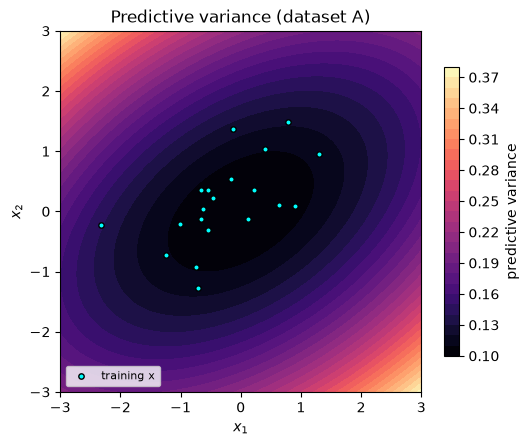

In [6]:
_, var_a = predictive(GRID, mean_a, cov_a, NOISE_VAR)
print(f"predictive variance: min {var_a.min():.4f}, max {var_a.max():.4f}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
plot_pred_var(ax, X_a, var_a, "Predictive variance (dataset A)")
fig.tight_layout()
fig.savefig(FIG_DIR / "predictive_var_A.png", dpi=150)
plt.show()

- At the origin the variance equals the noise level 0.1, because $x^T\Sigma x = 0$ when $x = 0$.
- It grows as we move away from the origin, more slowly along the direction where the training points lie.

## D. Squeeze the inputs along $x_1$

Now $x \sim \mathcal N(0, \Sigma_x)$ with $\Sigma_x = \mathrm{diag}(0.1, 1)$, so the training points form a narrow vertical strip. We rerun the same steps and plot both datasets side by side, with a shared zoom window and colour scale.

$\Sigma_x = I$: mean [-1.088  1.008], std of theta [0.092 0.112], pred. variance range [0.100, 0.375]
$\Sigma_x = \mathrm{diag}(0.1, 1)$: mean [-1.206  0.995], std of theta [0.281 0.111], pred. variance range [0.100, 1.172]


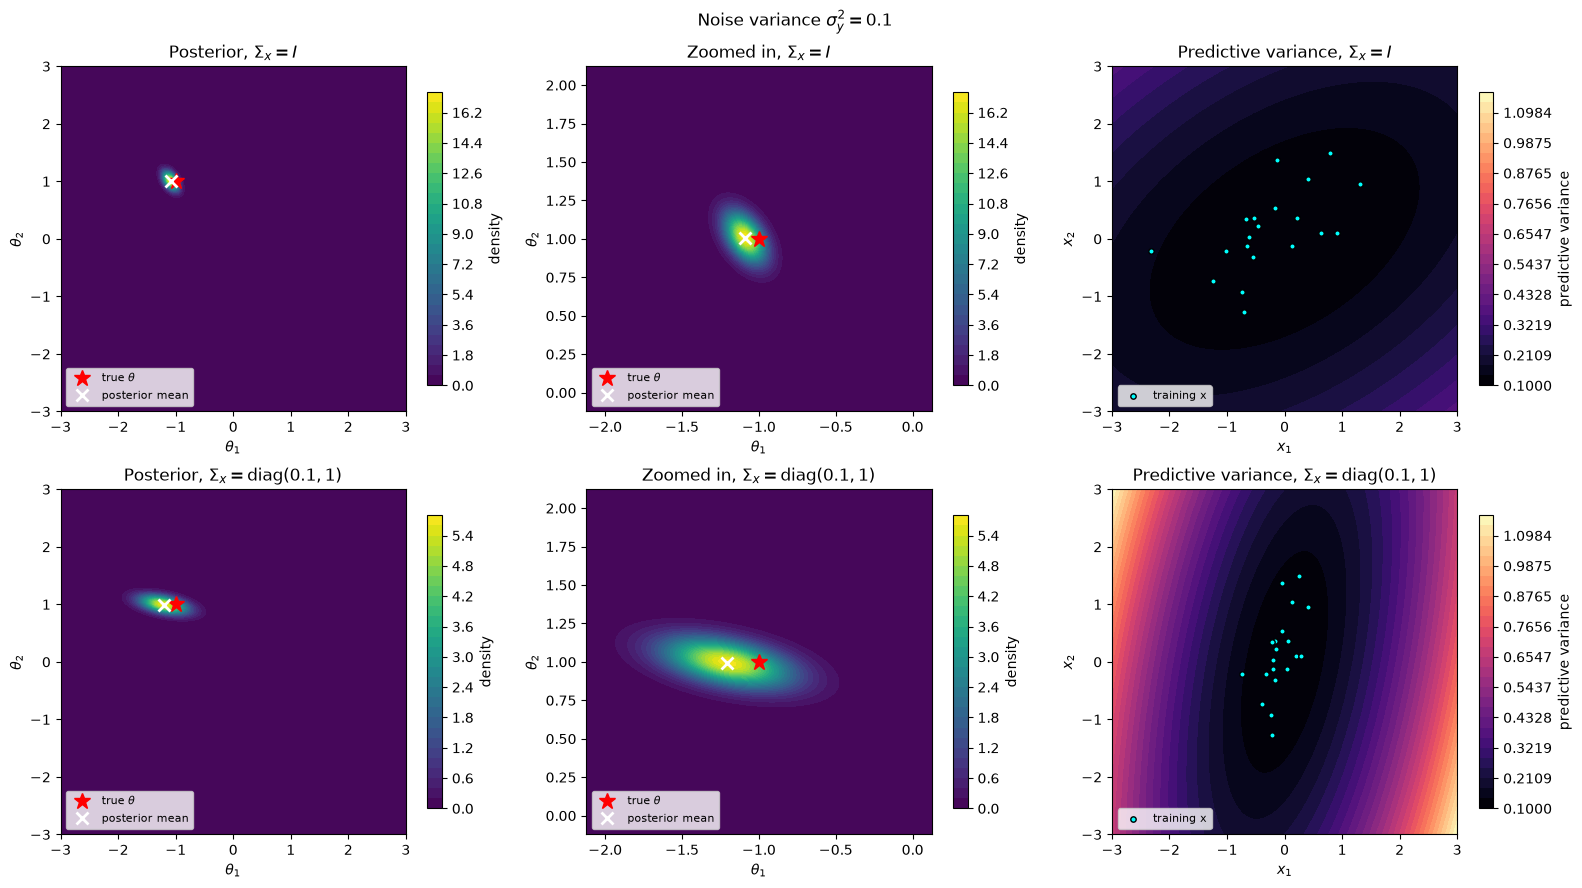

In [7]:
SIGMA_X_NARROW = np.diag([0.1, 1.0])
SETTINGS = {
    r"$\Sigma_x = I$": SIGMA_X,
    r"$\Sigma_x = \mathrm{diag}(0.1, 1)$": SIGMA_X_NARROW,
}


def compare(noise_var, fname):
    # Fit both input settings with the given noise level and plot them in one figure
    results = []
    for name, Sigma_x in SETTINGS.items():
        X, y = make_dataset(z, e, Sigma_x, noise_var)
        mean, cov = posterior(X, y, noise_var)
        _, var = predictive(GRID, mean, cov, noise_var)
        results.append((name, X, mean, cov, var))
        print(f"{name}: mean {mean.round(3)}, std of theta {np.sqrt(np.diag(cov)).round(3)}, "
              f"pred. variance range [{var.min():.3f}, {var.max():.3f}]")

    # Shared zoom window and colour scale so the two rows are directly comparable
    half = 4 * max(np.sqrt(np.diag(r[3])).max() for r in results)
    levels = np.linspace(noise_var, max(r[4].max() for r in results), 30)

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    for row, (name, X, mean, cov, var) in zip(axes, results):
        plot_posterior_pdf(row[0], mean, cov, f"Posterior, {name}")
        plot_posterior_pdf(row[1], mean, cov, f"Zoomed in, {name}", center=THETA_TRUE, half=half)
        plot_pred_var(row[2], X, var, f"Predictive variance, {name}", levels=levels)
    fig.suptitle(rf"Noise variance $\sigma_y^2 = {noise_var}$")
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=150)
    plt.show()


compare(0.1, "compare_noise_0.1.png")

**Why do they differ?**
- **Posterior:** much wider along $\theta_1$ (std 0.28 vs 0.09), while $\theta_2$ is unchanged. With almost no variation in $x_1$, the data can hardly show how $y$ depends on $x_1$.
- **Predictive variance:** rises steeply as we move left or right in $x_1$, away from the strip. The model is unsure where it has seen no data, and it says so.

### Less noise: $p(y \mid x) = \mathcal N(y; x^T\theta, 0.01)$

We repeat both datasets with noise variance 0.01.

$\Sigma_x = I$: mean [-1.031  1.007], std of theta [0.029 0.036], pred. variance range [0.010, 0.038]
$\Sigma_x = \mathrm{diag}(0.1, 1)$: mean [-1.092  1.005], std of theta [0.092 0.036], pred. variance range [0.010, 0.125]


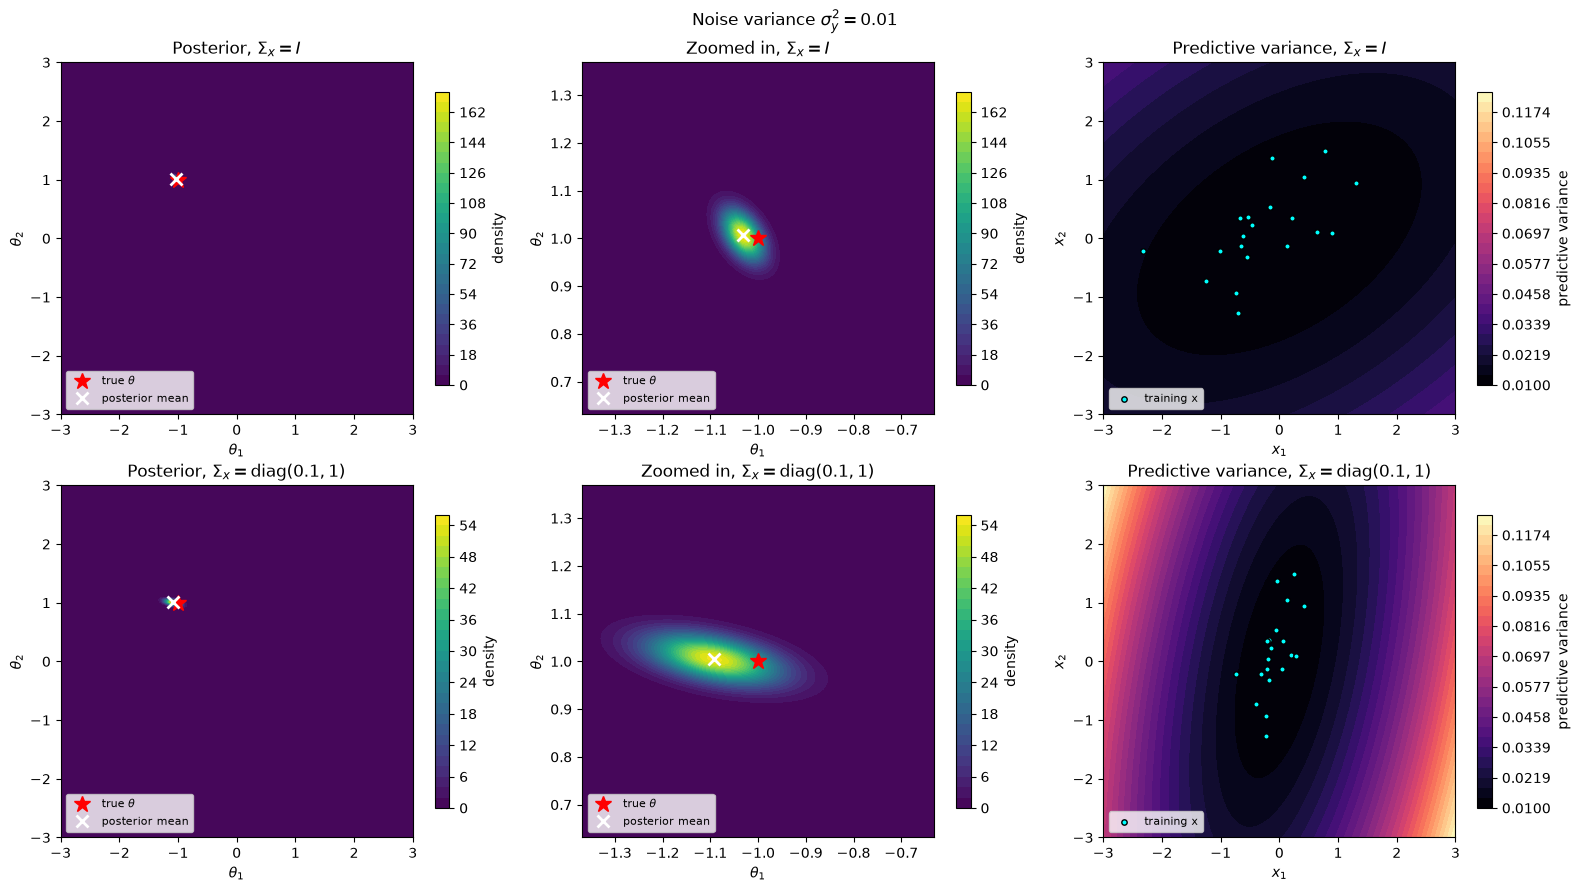

In [8]:
compare(0.01, "compare_noise_0.01.png")

**What changes?**
- Each label is 10 times more reliable, so the posterior shrinks about 3 times in each direction ($\sqrt{10} \approx 3$).
- The predicted variance drops about 10 times everywhere: the minimum is 0.01, and it grows more slowly away from the origin.
- The shapes stay the same: the squeezed dataset is still most unsure along $x_1$ and $\theta_1$. Only the scale changes.

**In short:** the model is only confident in the directions the data covers, and less noisy data makes it more confident overall without changing where it is unsure.